## Group 13

**Project Title:**  Early Detection of Dengue Infection Using Clinical Symptoms and Patient Data

**Lecturer:** Assoc. Prof. Dr. Kasturi Dewi Varathan

**Team Members:**
| Matric Number | Name              |
| ------------- | ----------------- |
| 24209652      | Sam Yee Thong Wah |
| 25081169      | XIAO SURUI        |
| 25081435      | SHI CHENGUANG     |
| 17046197      | Lai Seng Yew      |
| 25075827      | ZHU JIAYI         |
| 25090337      | Quek Jia Ming     |




## Section 1: Business Domain

### 1.1 Problem Statement

Despite long-standing dengue control programs, dengue remains endemic with recurring outbreaks, placing significant strain on public health systems.
Current challenges include:

1.   Heavy reliance on reactive vector control (fogging after outbreaks)
2.   Low public risk perception and compliance, especially outside outbreak periods
3.   Uniform policies that do not prioritize high‑risk populations
4.   Limited adoption of targeted dengue vaccination strategies, despite potential benefits

As a result, healthcare costs increase, hospital capacity is strained and dengue-related morbidity and mortality persist.

### 1.2 Business Objectives

To reduce dengue incidence, severity and outbreak impact through evidence based government policy, improved public awareness and targeted vaccination strategies for high risk population groups.

1.   Strengthen early prevention rather than reactive outbreak response
2.   Improve public compliance with dengue prevention measures
3.   Optimize allocation of limited public health resources
4.   Use data-driven insights to justify vaccination strategies for specific population groups

### 1.3 Data Mining Goal

Here, we are translating the government policy objective (Business Objective)into technical, analytical tasks that can be implemented by using data.

The main 2 data mining goal is to develop a predictive and risk profiling dengue analytics system that support

1.   Identify High-Risk Population Groups

     The goal is to identify high risk population groups by analyzing demographic, geographic, and health related factors. In details, the analysis will examine the relationship between age group, residential zone, gender, pregnancy status and medical history and also the likelihood of being classified as high risk. The results will support targeted intervention, prevention strategies and informed decision making for government health policy planning.


### 1.4 Project Plan

1.   Business Understanding (29 Mar ~ 4 Apr)
     - Defined dengue policy objectives on agreed problem statement and scope
     - Identify success criteria

2.   Data Understanding (5 Apr ~ 18 Apr)
     - Understanding of available dengue, demographic and environmental data.
     - Identify data gaps, quality issues and constraints.

3.   Data Preparation (19 Apr ~ 9 May)
     - Clean and integrate dataset for analysis
     - Identify and prepare variables for modeling and further analysis
     - Select the suitable dataset for modeling

4.   Modeling (10 May ~ 23 May)
     - Implement the dengue outbreaks predictive models

5.   Evaluation (24 May ~ 30 May)
     - Validate the model performance against the business goals

6.   Deployment (31 May ~ 6 Jun)
     - Dashboard for coninuous monitoring and future policy improvement
     - Evidence based recommendation for targeted awareness and vaccination programs.

## Section 2: Data Understanding

In this section, the dengue dataset is explored to gain a clear understanding of its structure, variables, and overall data quality before proceeding to data preparation and modelling.

### 2.1 Collect Data

multiple datasets are collected: such as....
describe all the datasets


The dataset `sinan-db.csv` was obtained from Brazil’s national notifiable disease surveillance system, **SINAN (Sistema de Informação de Agravos de Notificação)**, which collects mandatory reports of suspected and confirmed dengue cases from healthcare institutions across **Brazil**.

The dataset contains **individual-level dengue case records from 2015 to 2020**, where each row represents a single patient notification, including demographic, clinical, laboratory, and outcome-related information

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving sinan-db.csv to sinan-db (1).csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv('sinan-db.csv', low_memory=False)

print(f"Dataset Shape  : {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Years Covered  : {df['NU_ANO'].min()} – {df['NU_ANO'].max()}")
print(f"\nFirst 3 rows (selected columns):")
df[['NU_ANO','DT_NOTIFIC','CS_SEXO','NU_IDADE_N','CS_RACA',
    'CLASSI_FIN','EVOLUCAO','HOSPITALIZ','FEBRE','CEFALEIA']].head(3)

Dataset Shape  : 57,445 rows × 147 columns
Years Covered  : 2015 – 2020

First 3 rows (selected columns):


,NU_ANO,DT_NOTIFIC,CS_SEXO,NU_IDADE_N,CS_RACA,CLASSI_FIN,EVOLUCAO,HOSPITALIZ,FEBRE,CEFALEIA
0,2015,01/06/2015,M,4001,4.0,8.0,NaN,NaN,NaN,NaN
1,2015,08/06/2015,F,4070,4.0,8.0,NaN,NaN,NaN,NaN
2,2015,08/06/2015,F,4030,4.0,8.0,NaN,NaN,NaN,NaN


### 2.2 Describe Data (summarization of different datasets)

This dataset contains **147 columns**, which are grouped into logical categories to understand what type of information available.

In [ ]:
# Column group summary
column_groups = {
    'Notification / Admin'    : ['NU_NOTIFIC','TP_NOT','ID_AGRAVO','DT_NOTIFIC','SEM_NOT','NU_ANO','SG_UF_NOT'],
    'Patient Demographics'    : ['DT_NASC','NU_IDADE_N','CS_SEXO','CS_GESTANT','CS_RACA','CS_ESCOL_N','CS_ZONA','ID_OCUPA_N'],
    'Clinical Symptoms'       : ['FEBRE','MIALGIA','CEFALEIA','EXANTEMA','VOMITO','NAUSEA',
                                  'DOR_COSTAS','CONJUNTVIT','ARTRITE','ARTRALGIA',
                                  'PETEQUIA_N','LEUCOPENIA','LACO','DOR_RETRO'],
    'Comorbidities'           : ['DIABETES','HEMATOLOG','HEPATOPAT','RENAL',
                                  'HIPERTENSA','ACIDO_PEPT','AUTO_IMUNE'],
    'Lab Results'             : ['RESUL_SORO','RESUL_NS1','RESUL_VI_N','RESUL_PCR_','SOROTIPO'],
    'Hospitalization/Outcome' : ['HOSPITALIZ','DT_INTERNA','CLASSI_FIN','EVOLUCAO','DT_OBITO'],
    'Warning/Severity Signs'  : ['ALRM_HIPOT','ALRM_PLAQ','ALRM_VOM','GRAV_PULSO','GRAV_HIPOT'],
}

print("Column Group Summary:")
print(f"{'Group':<30} {'# Columns':<12} {'Examples'}")
print("-" * 80)
for grp, cols in column_groups.items():
    print(f"{grp:<30} {len(cols):<12} {', '.join(cols[:3])}...")

print(f"\nTotal columns in dataset: {df.shape[1]}")
print(f"Columns shown above     : {sum(len(v) for v in column_groups.values())}")
print(f"Remaining (admin/dates) : {df.shape[1] - sum(len(v) for v in column_groups.values())}")

Column Group Summary:
Group                          # Columns    Examples
--------------------------------------------------------------------------------
Notification / Admin           7            NU_NOTIFIC, TP_NOT, ID_AGRAVO...
Patient Demographics           8            DT_NASC, NU_IDADE_N, CS_SEXO...
Clinical Symptoms              14           FEBRE, MIALGIA, CEFALEIA...
Comorbidities                  7            DIABETES, HEMATOLOG, HEPATOPAT...
Lab Results                    5            RESUL_SORO, RESUL_NS1, RESUL_VI_N...
Hospitalization/Outcome        5            HOSPITALIZ, DT_INTERNA, CLASSI_FIN...
Warning/Severity Signs         5            ALRM_HIPOT, ALRM_PLAQ, ALRM_VOM...

Total columns in dataset: 147
Columns shown above     : 51
Remaining (admin/dates) : 96


**Column Group Descriptions:**

| Group | # Cols | Relevance to Goals |
|---|---|---|
| Notification / Admin | 7 | Year, week, region |
| Patient Demographics | 8 | Age, sex, education, occupation |
| Clinical Symptoms | 14 | 14 symptom flags |
| Comorbidities | 7 | Pre-existing conditions  |
| Lab Results | 5 | Serotype, confirmation |
| Hospitalization/Outcome | 5 | Severity, death |
| Warning/Severity Signs | 10+ | Alarm signals |
| Admin/Dates/System | ~90 | Largely system fields, mostly missing |

In [ ]:
# Data types overview
print("Data Types Summary:")
dtype_counts = df.dtypes.value_counts()
print(dtype_counts)
print(f"\nKey Column Data Types:")
key_cols = ['NU_ANO','DT_NOTIFIC','CS_SEXO','NU_IDADE_N','CS_RACA',
            'CLASSI_FIN','EVOLUCAO','FEBRE','DIABETES','HOSPITALIZ']
print(df[key_cols].dtypes.to_string())

Data Types Summary:
float64    111
object      27
int64        9
Name: count, dtype: int64

Key Column Data Types:
NU_ANO          int64
DT_NOTIFIC     object
CS_SEXO        object
NU_IDADE_N      int64
CS_RACA       float64
CLASSI_FIN    float64
EVOLUCAO      float64
FEBRE         float64
DIABETES      float64
HOSPITALIZ    float64


###2.3 Explore Data

This section explore the raw data across 6 dimensions to understand what it looks like **before any cleaning or transformation**.

#### 2.3.1 Basic Dataset Profile

In [ ]:
print(f"Rows         : {df.shape[0]:,}")
print(f"Columns      : {df.shape[1]}")
#print(f"Memory Usage : {df.memory_usage(deep=True).sum() / 1024**2:.1f} MB")
print(f"\nDate range of notifications:")
print(f"  Earliest : {df['DT_NOTIFIC'].min()}")
print(f"  Latest   : {df['DT_NOTIFIC'].max()}")
print(f"\nCases per year (raw count):")
print(df['NU_ANO'].value_counts().sort_index().to_string())

Rows         : 57,445
Columns      : 147

Date range of notifications:
  Earliest : 01/01/2015
  Latest   : 31/12/2019

Cases per year (raw count):
NU_ANO
2015     8427
2016    16622
2017     8952
2018     4974
2019     7994
2020    10476


#### 2.3.2 Key Categorical Column Variables

In [ ]:
# Decode key categorical variables

# Mapping dictionaries
sex_map = {'M': 'Male', 'F': 'Female', 'I': 'Unknown'}

classi_map = {
    1: 'Dengue',
    2: 'Discarded',
    5: 'Dengue',
    8: 'Severe Dengue',
    10: 'Dengue w/ Warning Signs',
    11: 'Dengue w/ Warning Signs',
    12: 'Severe Dengue',
    13: 'Chikungunya'
}

evolucao_map = {
    1: 'Cured',
    2: 'Death (Dengue)',
    3: 'Death (Other)',
    9: 'Unknown'
}

hospitaliz_map = {
    1: 'Yes',
    2: 'No',
    9: 'Unknown'
}

zona_map = {
    1: 'Urban',
    2: 'Rural',
    3: 'Peri-urban',
    9: 'Unknown'
}

gest_map = {
    1: '1st Trimester',
    2: '2nd Trimester',
    3: '3rd Trimester',
    4: 'Not Pregnant',
    5: 'Unknown'
}


def show_counts(series, title):
    print("\n" + "=" * 60)
    print(title)
    print("=" * 60)

    counts = series.fillna("Unknown").value_counts()
    percentages = (counts / counts.sum() * 100).round(2)

    result = pd.DataFrame({
        'Count': counts,
        'Percentage (%)': percentages
    })

    print(result.to_string())

# Patient Sex
show_counts(df['CS_SEXO'].map(sex_map), "CS_SEXO — Patient Sex")

# Dengue Classification
show_counts(df['CLASSI_FIN'].map(classi_map), "CLASSI_FIN — Dengue Classification")

# Outcome
show_counts(df['EVOLUCAO'].map(evolucao_map), "EVOLUCAO — Patient Outcome")

# Hospitalization
show_counts(df['HOSPITALIZ'].map(hospitaliz_map), "HOSPITALIZ — Hospitalised")

# Living Area
show_counts(df['CS_ZONA'].map(zona_map), "CS_ZONA — Living Area")



CS_SEXO — Patient Sex
         Count  Percentage (%)
CS_SEXO                       
Female   30212           52.59
Male     27207           47.36
Unknown     26            0.05

CLASSI_FIN — Dengue Classification
                         Count  Percentage (%)
CLASSI_FIN                                    
Dengue                   28659           49.89
Dengue w/ Warning Signs  14447           25.15
Severe Dengue            13104           22.81
Unknown                    602            1.05
Discarded                  386            0.67
Chikungunya                247            0.43

EVOLUCAO — Patient Outcome
                Count  Percentage (%)
EVOLUCAO                             
Cured           35564           61.91
Unknown         21798           37.95
Death (Other)      66            0.11
Death (Dengue)     17            0.03

HOSPITALIZ — Hospitalised
            Count  Percentage (%)
HOSPITALIZ                       
No          36089           62.82
Unknown     19641        

#### 2.3.3 Dengue Case Count by Year

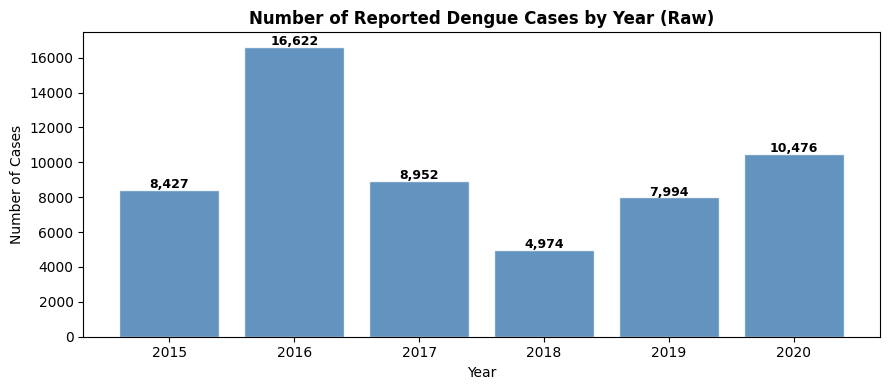

Year-on-year case counts:
  2015: 8,427 cases
  2016: 16,622 cases
  2017: 8,952 cases
  2018: 4,974 cases
  2019: 7,994 cases
  2020: 10,476 cases


In [ ]:
yearly = df['NU_ANO'].value_counts().sort_index().reset_index()
yearly.columns = ['Year', 'Cases']

plt.figure(figsize=(9, 4))
bars = plt.bar(yearly['Year'].astype(str), yearly['Cases'],
               color='steelblue', edgecolor='white', alpha=0.85)
for bar, val in zip(bars, yearly['Cases']):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100,
             f'{val:,}', ha='center', fontsize=9, fontweight='bold')
plt.title('Number of Reported Dengue Cases by Year (Raw)', fontweight='bold', fontsize=12)
plt.xlabel('Year')
plt.ylabel('Number of Cases')
plt.tight_layout()
plt.show()

print("Year-on-year case counts:")
for _, row in yearly.iterrows():
    print(f"  {int(row['Year'])}: {int(row['Cases']):,} cases")

#### 2.3.4 Raw Age Distribution

Age is encoded as `NU_IDADE_N` where the first digit = unit (4=years).

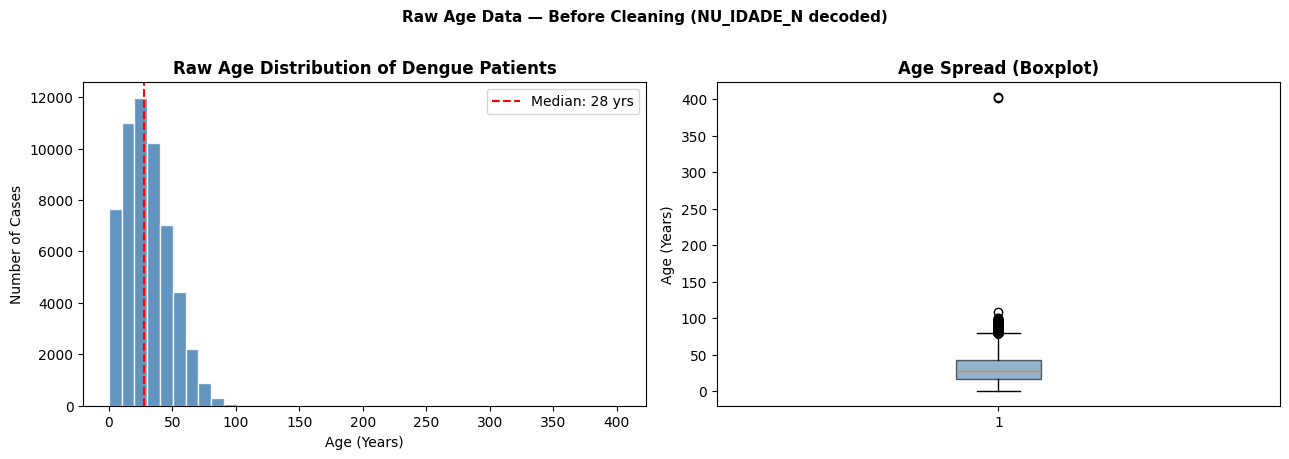

Age Stats:
  Min    : 0
  Max    : 403
  Mean   : 30.2
  Median : 28
  Std    : 18.0

Records with age > 100: 3


In [ ]:
# Decode age in years (prefix 4 = years)
df['AGE_YEARS_RAW'] = df['NU_IDADE_N'].apply(
    lambda x: int(str(int(x))[1:]) if pd.notna(x) and str(int(x))[0]=='4' else np.nan
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Histogram
axes[0].hist(df['AGE_YEARS_RAW'].dropna(), bins=40, color='steelblue', edgecolor='white', alpha=0.85)
axes[0].axvline(df['AGE_YEARS_RAW'].median(), color='red', linestyle='--', linewidth=1.5,
                label=f"Median: {df['AGE_YEARS_RAW'].median():.0f} yrs")
axes[0].set_title('Raw Age Distribution of Dengue Patients', fontweight='bold')
axes[0].set_xlabel('Age (Years)')
axes[0].set_ylabel('Number of Cases')
axes[0].legend()

# Boxplot
axes[1].boxplot(df['AGE_YEARS_RAW'].dropna(), vert=True, patch_artist=True,
                boxprops=dict(facecolor='steelblue', alpha=0.6))
axes[1].set_title('Age Spread (Boxplot)', fontweight='bold')
axes[1].set_ylabel('Age (Years)')

plt.suptitle('Raw Age Data — Before Cleaning (NU_IDADE_N decoded)',
             fontweight='bold', fontsize=11, y=1.01)
plt.tight_layout()
plt.show()

print(f"Age Stats:")
print(f"  Min    : {df['AGE_YEARS_RAW'].min():.0f}")
print(f"  Max    : {df['AGE_YEARS_RAW'].max():.0f}")
print(f"  Mean   : {df['AGE_YEARS_RAW'].mean():.1f}")
print(f"  Median : {df['AGE_YEARS_RAW'].median():.0f}")
print(f"  Std    : {df['AGE_YEARS_RAW'].std():.1f}")
print(f"\nRecords with age > 100: {(df['AGE_YEARS_RAW'] > 100).sum()}")

#### 2.3.5 Symptom and Comorbidity Prevalence

Each symptom and comorbidity is encoded as 1=Yes, 2=No. We calculate **raw prevalence** across all cases.

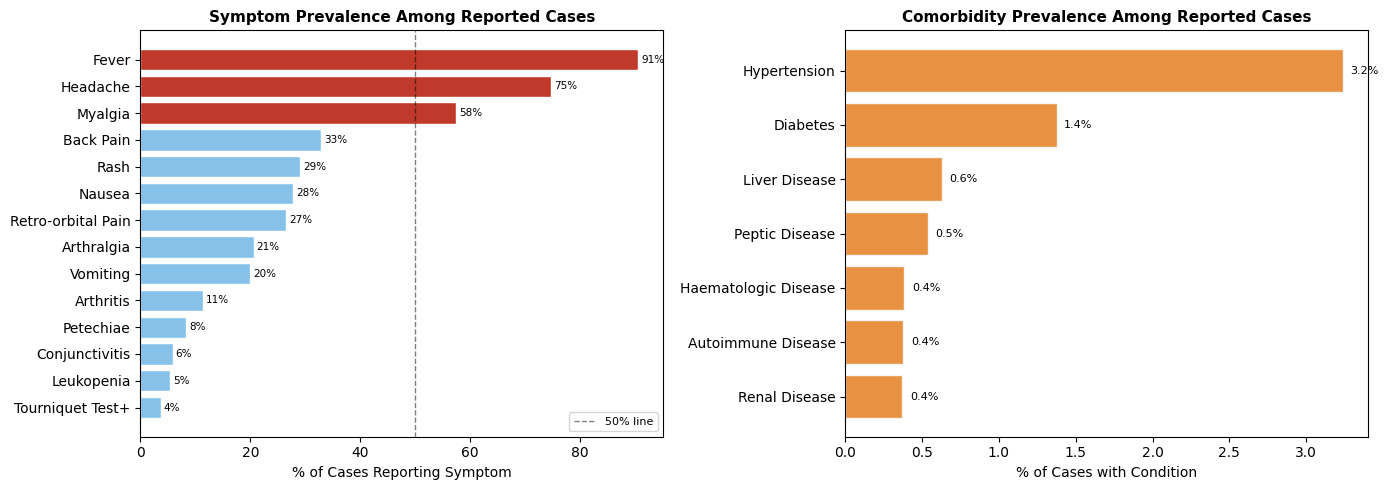

In [ ]:
symptoms = {
    'FEBRE'     : 'Fever',
    'CEFALEIA'  : 'Headache',
    'MIALGIA'   : 'Myalgia',
    'DOR_COSTAS': 'Back Pain',
    'DOR_RETRO' : 'Retro-orbital Pain',
    'NAUSEA'    : 'Nausea',
    'VOMITO'    : 'Vomiting',
    'ARTRALGIA' : 'Arthralgia',
    'ARTRITE'   : 'Arthritis',
    'EXANTEMA'  : 'Rash',
    'PETEQUIA_N': 'Petechiae',
    'LEUCOPENIA': 'Leukopenia',
    'CONJUNTVIT': 'Conjunctivitis',
    'LACO'      : 'Tourniquet Test+',
}
comorbidities = {
    'DIABETES'  : 'Diabetes',
    'HIPERTENSA': 'Hypertension',
    'ACIDO_PEPT': 'Peptic Disease',
    'HEPATOPAT' : 'Liver Disease',
    'RENAL'     : 'Renal Disease',
    'HEMATOLOG' : 'Haematologic Disease',
    'AUTO_IMUNE': 'Autoimmune Disease',
}

# Calculate % present (value=1) among those who have a recorded answer
def pct_yes(col):
    valid = df[col].dropna()
    return (valid == 1).sum() / len(valid) * 100

symp_pct  = {v: pct_yes(k) for k,v in symptoms.items()}
comor_pct = {v: pct_yes(k) for k,v in comorbidities.items()}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Symptoms
symp_df = pd.DataFrame(list(symp_pct.items()), columns=['Symptom','Prevalence_%'])
symp_df = symp_df.sort_values('Prevalence_%', ascending=True)
colors_s = ['#C0392B' if v > 50 else '#85C1E9' for v in symp_df['Prevalence_%']]
axes[0].barh(symp_df['Symptom'], symp_df['Prevalence_%'], color=colors_s, edgecolor='white')
axes[0].axvline(50, color='black', linestyle='--', linewidth=1, alpha=0.5, label='50% line')
axes[0].set_title('Symptom Prevalence Among Reported Cases', fontweight='bold', fontsize=11)
axes[0].set_xlabel('% of Cases Reporting Symptom')
axes[0].legend(fontsize=8)
for i, (_, row) in enumerate(symp_df.iterrows()):
    axes[0].text(row['Prevalence_%'] + 0.5, i, f"{row['Prevalence_%']:.0f}%", va='center', fontsize=7.5)

# Comorbidities
comor_df = pd.DataFrame(list(comor_pct.items()), columns=['Condition','Prevalence_%'])
comor_df = comor_df.sort_values('Prevalence_%', ascending=True)
axes[1].barh(comor_df['Condition'], comor_df['Prevalence_%'], color='#E67E22', edgecolor='white', alpha=0.85)
axes[1].set_title('Comorbidity Prevalence Among Reported Cases', fontweight='bold', fontsize=11)
axes[1].set_xlabel('% of Cases with Condition')
for i, (_, row) in enumerate(comor_df.iterrows()):
    axes[1].text(row['Prevalence_%'] + 0.05, i, f"{row['Prevalence_%']:.1f}%", va='center', fontsize=8)

plt.tight_layout()
plt.show()

#### 2.3.6 Raw Dengue Severity Classification Distribution

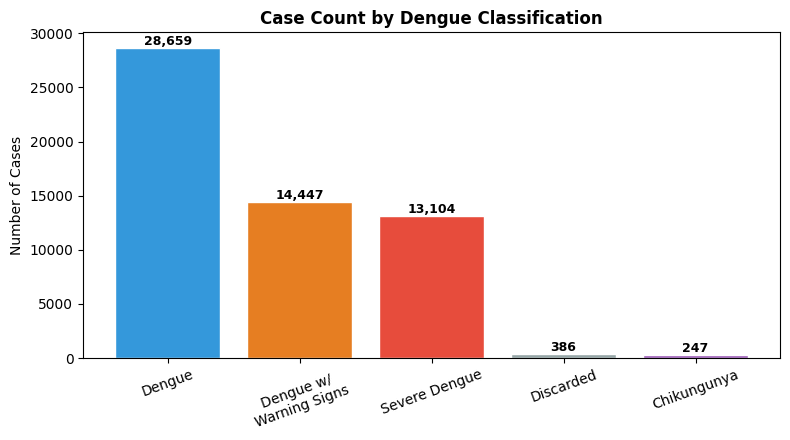

In [ ]:
classi_map = {
    1.0:'Dengue', 2.0:'Discarded', 5.0:'Dengue',
    8.0:'Severe Dengue', 10.0:'Dengue w/\nWarning Signs',
    11.0:'Dengue w/\nWarning Signs', 12.0:'Severe Dengue',
    13.0:'Chikungunya'
}

# Map labels
df['CLASSI_LABEL'] = df['CLASSI_FIN'].map(classi_map)

# Count values
classi_counts = df['CLASSI_LABEL'].value_counts()

# Create SINGLE plot
plt.figure(figsize=(8, 4.5))

palette_c = {
    'Dengue':'#3498DB',
    'Dengue w/\nWarning Signs':'#E67E22',
    'Severe Dengue':'#E74C3C',
    'Discarded':'#95A5A6',
    'Chikungunya':'#9B59B6'
}

colors_c = [palette_c.get(c, '#BDC3C7') for c in classi_counts.index]

# Bar chart
bars = plt.bar(classi_counts.index, classi_counts.values,
               color=colors_c, edgecolor='white')

for bar, val in zip(bars, classi_counts.values):
    plt.text(bar.get_x() + bar.get_width()/2,
             bar.get_height(),
             f'{val:,}',
             ha='center', va='bottom',
             fontsize=9, fontweight='bold')

plt.title('Case Count by Dengue Classification', fontweight='bold')
plt.ylabel('Number of Cases')
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

### 2.4 Data Quality Check

This section check for missing values, duplicates, and structural anomalies.

#### 2.4.1 Missing Value Check

In [ ]:
# Missing Value Check
missing     = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(1)
missing_df  = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
missing_df  = missing_df.sort_values('Missing %', ascending=False)

# Categorise missingness
fully_missing   = missing_df[missing_df['Missing %'] == 100]
heavily_missing = missing_df[(missing_df['Missing %'] > 50) & (missing_df['Missing %'] < 100)]
partially_missing = missing_df[(missing_df['Missing %'] > 0) & (missing_df['Missing %'] <= 50)]
complete_cols   = missing_df[missing_df['Missing %'] == 0]

print(f"Fully missing (100%)    : {len(fully_missing)} columns")
print(f"Heavily missing (>50%)  : {len(heavily_missing)} columns")
print(f"Partially missing (>0%) : {len(partially_missing)} columns")
print(f"Complete (0% missing)   : {len(complete_cols)} columns")

print(f"\nComplete columns (0% missing):")
print(complete_cols.index.tolist())

print(f"\nPartially missing columns (>0% and ≤50%):")
print(partially_missing[['Missing %']].to_string())

Fully missing (100%)    : 21 columns
Heavily missing (>50%)  : 67 columns
Partially missing (>0%) : 40 columns
Complete (0% missing)   : 21 columns

Complete columns (0% missing):
['SG_UF', 'NU_NOTIFIC', 'TP_NOT', 'ID_AGRAVO', 'DT_NOTIFIC', 'Unnamed: 0', 'CS_GESTANT', 'NU_IDADE_N', 'CS_SEXO', 'ID_REGIONA', 'ID_UNIDADE', 'DT_SIN_PRI', 'SEM_PRI', 'ID_MUNICIP', 'SG_UF_NOT', 'NU_ANO', 'SEM_NOT', 'ID_MN_RESI', 'ID_PAIS', 'ID_RG_RESI', 'CS_FLXRET']

Partially missing columns (>0% and ≤50%):
               Missing %
RESUL_NS1           49.2
RESUL_SORO          40.3
EVOLUCAO            35.6
PETEQUIA_N          32.7
ARTRALGIA           32.7
DOR_RETRO           32.7
DIABETES            32.7
HEMATOLOG           32.7
HEPATOPAT           32.7
FEBRE               32.7
CEFALEIA            32.7
EXANTEMA            32.7
NAUSEA              32.7
MIALGIA             32.7
VOMITO              32.7
AUTO_IMUNE          32.7
LEUCOPENIA          32.7
RENAL               32.7
HIPERTENSA          32.7
ACIDO_PEPT

#### 2.4.2 Duplicate Check

In [ ]:
print(f"Fully duplicate rows    : {df.duplicated().sum()}")

#print(f"\nNotification IDs — unique: {df['NU_NOTIFIC'].nunique():,} / total: {len(df):,}")

Fully duplicate rows    : 0


## Section 3: Data Preparation
Clean and shape the data to prepare for modeling

## 3.0 Data Format
Translating Foreign language data into English for the ease of data analysis


In [ ]:
#!pip install deep_translator
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
##from deep_translator import GoogleTranslator
##translator = GoogleTranslator(source='pt', target='en')

# Load dataset
#df = pd.read_csv('sinan-db.csv', low_memory=False)
df2=df
df2.info()
print("Original dataset with columns in foreign language")
print(df2.head(5))
translate_map = {
    "NU_NOTIFIC": "Notification Number",
    "TP_NOT": "Notification Type",
    "ID_AGRAVO": "Disease ID",
    "DT_NOTIFIC": "Notification Date",
    "SEM_NOT": "Notification Week",
    "NU_ANO": "Year",
    "SG_UF_NOT": "State of Notification",
    "ID_MUNICIP": "Municipality ID",
    "ID_REGIONA": "Health Region ID",
    "ID_UNIDADE": "Health Unit ID",
    "DT_SIN_PRI": "Date of First Symptoms",
    "SEM_PRI": "Symptom Week",
    "DT_NASC": "Date of Birth",
    "SOUNDEX": "Name Soundex Code",
    "NU_IDADE_N": "Age",
    "CS_SEXO": "Sex",
    "CS_GESTANT": "Pregnancy Status",
    "CS_RACA": "Race/Ethnicity",
    "CS_ESCOL_N": "Education Level",
    "SG_UF": "State of Residence",
    "ID_MN_RESI": "Municipality of Residence ID",
    "ID_RG_RESI": "Region of Residence ID",
    "ID_DISTRIT": "District ID",
    "ID_BAIRRO": "Neighborhood ID",
    "NM_BAIRRO": "Neighborhood Name",
    "ID_GEO1": "Geographic Location 1",
    "ID_GEO2": "Geographic Location 2",
    "CS_ZONA": "Zone (Urban/Rural)",
    "ID_PAIS": "Country ID",
    "DT_INVEST": "Investigation Date",
    "ID_OCUPA_N": "Occupation ID",
    "FEBRE": "Fever",
    "MIALGIA": "Myalgia (Muscle Pain)",
    "CEFALEIA": "Headache",
    "EXANTEMA": "Rash (Exanthema)",
    "VOMITO": "Vomiting",
    "NAUSEA": "Nausea",
    "DOR_COSTAS": "Back Pain",
    "CONJUNTVIT": "Conjunctivitis",
    "ARTRITE": "Arthritis",
    "ARTRALGIA": "Arthralgia (Joint Pain)",
    "PETEQUIA_N": "Petechiae",
    "LEUCOPENIA": "Leukopenia",
    "LACO": "Tourniquet Test (Laco test)",
    "DOR_RETRO": "Retro-orbital Pain",
    "DIABETES": "Diabetes",
    "HEMATOLOG": "Hematologic Disease",
    "HEPATOPAT": "Hepatopathy (Liver Disease)",
    "RENAL": "Renal (Kidney Disease)",
    "HIPERTENSA": "Hypertension",
    "ACIDO_PEPT": "Peptic Acid Disease",
    "AUTO_IMUNE": "Autoimmune Disease",
    "DT_CHIK_S1": "Date of Chikungunya Sample 1",
    "DT_CHIK_S2": "Date of Chikungunya Sample 2",
    "DT_PRNT": "PRNT Test Date",
    "RES_CHIKS1": "Result Chikungunya Sample 1",
    "RES_CHIKS2": "Result Chikungunya Sample 2",
    "RESUL_PRNT": "PRNT Result",
    "DT_SORO": "Serology Date",
    "RESUL_SORO": "Serology Result",
    "DT_NS1": "NS1 Test Date",
    "RESUL_NS1": "NS1 Result",
    "DT_VIRAL": "Viral Isolation Date",
    "RESUL_VI_N": "Viral Isolation Result",
    "DT_PCR": "PCR Date",
    "RESUL_PCR_": "PCR Result",
    "SOROTIPO": "Serotype",
    "HISTOPA_N": "Histopathology Result",
    "IMUNOH_N": "Immunohistochemistry Result",
    "HOSPITALIZ": "Hospitalization Status",
    "DT_INTERNA": "Date of Hospitalization",
    "UF": "State",
    "MUNICIPIO": "Municipality",
    "HOSPITAL": "Hospital Name",
    "DDD_HOSP": "Hospital Area Code",
    "TEL_HOSP": "Hospital Phone Number",
    "TPAUTOCTO": "Autochthonous Case Type",
    "COUFINF": "State of Infection",
    "COPAISINF": "Country of Infection",
    "COMUNINF": "Municipality of Infection",
    "CODISINF": "District of Infection",
    "CO_BAINF": "Neighborhood of Infection ID",
    "NOBAIINF": "Neighborhood of Infection Name",
    "CLASSI_FIN": "Final Classification",
    "CRITERIO": "Confirmation Criteria",
    "DOENCA_TRA": "Transmitted Disease",
    "CLINC_CHIK": "Chikungunya Clinical Form",
    "EVOLUCAO": "Outcome/Evolution",
    "DT_OBITO": "Date of Death",
    "DT_ENCERRA": "Date of Case Closing",
    "ALRM_HIPOT": "Warning Sign: Hypotension",
    "ALRM_PLAQ": "Warning Sign: Platelet Decrease",
    "ALRM_VOM": "Warning Sign: Persistent Vomiting",
    "ALRM_SANG": "Warning Sign: Mucosal Bleeding",
    "ALRM_HEMAT": "Warning Sign: Hematocrit Increase",
    "ALRM_ABDOM": "Warning Sign: Abdominal Pain",
    "ALRM_LETAR": "Warning Sign: Lethargy/Irritability",
    "ALRM_HEPAT": "Warning Sign: Hepatomegaly",
    "ALRM_LIQ": "Warning Sign: Fluid Accumulation",
    "DT_ALRM": "Date of Warning Signs",
    "GRAV_PULSO": "Severity: Weak/Imperectible Pulse",
    "GRAV_CONV": "Severity: Convulsions",
    "GRAV_ENCH": "Severity: Capillary Refill > 2s",
    "GRAV_INSUF": "Severity: Respiratory Failure",
    "GRAV_TAQUI": "Severity: Tachycardia",
    "GRAV_EXTRE": "Severity: Cold Extremities",
    "GRAV_HIPOT": "Severity: Hypotension",
    "GRAV_HEMAT": "Severity: Hematemesis",
    "GRAV_MELEN": "Severity: Melena",
    "GRAV_METRO": "Severity: Metrorrhagia",
    "GRAV_SANG": "Severity: Major Bleeding",
    "GRAV_AST": "Severity: AST/ALT > 1000",
    "GRAV_MIOC": "Severity: Myocarditis",
    "GRAV_CONSC": "Severity: Impaired Consciousness",
    "GRAV_ORGAO": "Severity: Organ Damage",
    "DT_GRAV": "Date of Severity Signs",
    "MANI_HEMOR": "Hemorrhagic Manifestations",
    "EPISTAXE": "Epistaxis (Nosebleed)",
    "GENGIVO": "Gingival Bleeding",
    "METRO": "Metrorrhagia (Vaginal Bleeding)",
    "PETEQUIAS": "Petechiae",
    "HEMATURA": "Hematuria",
    "SANGRAM": "Other Bleeding",
    "LACO_N": "Tourniquet Test Result (Numeric)",
    "PLASMATICO": "Plasma Leakage",
    "EVIDENCIA": "Evidence",
    "PLAQ_MENOR": "Lowest Platelet Count",
    "CON_FHD": "DHF Confirmation (Dengue Hemorrhagic Fever)",
    "COMPLICA": "Complications",
    "NU_LOTE_I": "Batch Number I",
    "DS_OBS": "Observations",
    "TP_SISTEMA": "System Type",
    "NDUPLIC_N": "Duplicate Case Identifier",
    "DT_DIGITA": "Date of Entry/Typing",
    "DT_TRANSUS": "Transmission Date (SUS)",
    "DT_TRANSDM": "Transmission Date (Municipality)",
    "DT_TRANSSM": "Transmission Date (Municipal Health Secretariat)",
    "DT_TRANSRM": "Transmission Date (Regional)",
    "DT_TRANSRS": "Transmission Date (State)",
    "DT_TRANSSE": "Transmission Date (Federal)",
    "NU_LOTE_V": "Batch Number V",
    "NU_LOTE_H": "Batch Number H",
    "CS_FLXRET": "Return Flow Status",
    "FLXRECEBI": "Receipt Flow Status",
    "IDENT_MICR": "Micro-region Identifier",
    "MIGRADO_W": "Migrated Web Case"
}


df2_translate=df2.rename(columns=translate_map)
print("\nAfter translating the columns from foreign language to English for the ease of data analysis\n")
print(df2_translate.head(5))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 57445 entries, 0 to 57444
Columns: 149 entries, Unnamed: 0 to CLASSI_LABEL
dtypes: float64(112), int64(9), object(28)
memory usage: 65.3+ MB
Original dataset with columns in foreign language
   Unnamed: 0  NU_NOTIFIC  TP_NOT ID_AGRAVO  DT_NOTIFIC  SEM_NOT  NU_ANO  \
0           0       50375       2       A90  01/06/2015   201522    2015   
1           1       50398       2       A90  08/06/2015   201523    2015   
2           2       50381       2       A90  08/06/2015   201523    2015   
3           3       50352       2       A90  11/05/2015   201519    2015   
4           4       50328       2       A90  11/05/2015   201519    2015   

   SG_UF_NOT  ID_MUNICIP  ID_REGIONA  ...  DT_TRANSRS DT_TRANSSE  NU_LOTE_V  \
0         13      130040      5584.0  ...         NaN        NaN        NaN   
1         13      130040      5584.0  ...         NaN        NaN        NaN   
2         13      130040      5584.0  ...         NaN        NaN 

## 3.1 Data Cleaning - Removing NaN column with more than 5% of missing values

In [ ]:
#df_my.info()

#Remove col with more than 5% of NA data
#print(df2_translate.isna().sum())
df2_naseries=df2_translate.isna().sum()
#df_filter_sr=pd.Series(dtype='float')

df_filter_sr=df2_translate.copy()
#drop the 1st meaningless column (numbering)
df_filter_sr.drop(columns=[df_filter_sr.columns[0]], inplace=True)
missing_percentage=[]

#Calculate
for index,value in df2_naseries.items():
  #print("\nMissing data in column",index, "number=",value)
  #print("\nPercentage of missing data in column",index, "=", value/len(df2_translate[index])*100,"%\n")
  missing_percentage.append(value/len(df2_translate[index])*100)
  if( (value/len(df2_translate[index])*100 >5) and (index in df_filter_sr.columns)):
    print("Drop column=",index, "Missing % =",value/len(df2_translate[index])*100,"% \n")
    df_filter_sr.drop(columns=[index], inplace=True)


Drop column= Name Soundex Code Missing % = 98.91722517190355 % 

Drop column= Education Level Missing % = 29.09391591957525 % 

Drop column= District ID Missing % = 58.44546957959788 % 

Drop column= Neighborhood ID Missing % = 18.44198798851075 % 

Drop column= Geographic Location 1 Missing % = 99.98433284010792 % 

Drop column= Geographic Location 2 Missing % = 99.99825920445645 % 

Drop column= Investigation Date Missing % = 11.08364522586822 % 

Drop column= Occupation ID Missing % = 63.04116981460528 % 

Drop column= Fever Missing % = 32.66254678388023 % 

Drop column= Myalgia (Muscle Pain) Missing % = 32.66254678388023 % 

Drop column= Headache Missing % = 32.66254678388023 % 

Drop column= Rash (Exanthema) Missing % = 32.66254678388023 % 

Drop column= Vomiting Missing % = 32.66254678388023 % 

Drop column= Nausea Missing % = 32.66254678388023 % 

Drop column= Back Pain Missing % = 32.66254678388023 % 

Drop column= Conjunctivitis Missing % = 32.66254678388023 % 

Drop column= A

In [ ]:
print("Before data filtering:\n")
df2_translate.info()
print("\nBefore removing NaN, no.Columns=",len(df2_translate.columns))
print("\nAfter data filtering:\n")
df_filter_sr.info()
print("\nAfter removed NaN, no.Columns=",len(df_filter_sr.columns))

Before data filtering:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 57445 entries, 0 to 57444
Columns: 149 entries, Unnamed: 0 to CLASSI_LABEL
dtypes: float64(112), int64(9), object(28)
memory usage: 65.3+ MB

Before removing NaN, no.Columns= 149

After data filtering:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 57445 entries, 0 to 57444
Data columns (total 31 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Notification Number           57445 non-null  int64  
 1   Notification Type             57445 non-null  int64  
 2   Disease ID                    57445 non-null  object 
 3   Notification Date             57445 non-null  object 
 4   Notification Week             57445 non-null  int64  
 5   Year                          57445 non-null  int64  
 6   State of Notification         57445 non-null  int64  
 7   Municipality ID               57445 non-null  int64  
 8   Health Region ID   

## 3.2 Identifying outliers

In [ ]:
#checking outliers using IQR method
#agecol=df_filter_sr["Age"]
# Decode age in years (prefix 4 = years)
df_filter_sr['AGE_YEARS_DECODED'] = df_filter_sr["Age"].apply(
    lambda x: int(str(int(x))[1:]) if pd.notna(x) and str(int(x))[0]=='4' else np.nan
)
agecol=df_filter_sr["AGE_YEARS_DECODED"]
print(agecol.describe())
#print(agecol)
Q1age=agecol.quantile(0.25)
Q3age=agecol.quantile(0.75)
IQRage=Q3age-Q1age
upperfenceAge= Q3age + 1.5*IQRage
lowerfenceAge= Q1age - 1.5*IQRage
print("\nQ1=",Q1age,"Q3=",Q3age,"IRQ=",IQRage,"UpperfenceAge=",upperfenceAge,"LowerfenceAge",lowerfenceAge)
Flag_Age_Outliers= agecol[(agecol < lowerfenceAge) | (agecol > upperfenceAge)]
print("\nFlagged outliers Age:\n")
print(Flag_Age_Outliers)
print("\nSome outliers age have 80+ and 90+ which are still acceptable, hence not filtered out\n")
Flag_Age_Outliers2= agecol[(agecol > 120)]
print("\nFlagged outliers Age more than 120 y.o.:\n")
print(Flag_Age_Outliers2)

df_filter_sr2=df_filter_sr.copy()
for i in Flag_Age_Outliers2.index:
    print("\nData rows with ages more than 120 y.o are removed, age=",df_filter_sr2.at[i,"AGE_YEARS_DECODED"],'index=',i)
    df_filter_sr2.drop(i, inplace=True)

#print(df_filter_sr2.info())

count    55756.000000
mean        30.191943
std         17.993197
min          0.000000
25%         17.000000
50%         28.000000
75%         42.000000
max        403.000000
Name: AGE_YEARS_DECODED, dtype: float64

Q1= 17.0 Q3= 42.0 IRQ= 25.0 UpperfenceAge= 79.5 LowerfenceAge -20.5

Flagged outliers Age:

169      84.0
236      85.0
318      82.0
395      83.0
497      82.0
         ... 
56636    80.0
57016    93.0
57311    80.0
57372    84.0
57410    86.0
Name: AGE_YEARS_DECODED, Length: 436, dtype: float64

Some outliers age have 80+ and 90+ which are still acceptable, hence not filtered out


Flagged outliers Age more than 120 y.o.:

44634    401.0
55006    403.0
Name: AGE_YEARS_DECODED, dtype: float64

Data rows with ages more than 120 y.o are removed, age= 401.0 index= 44634

Data rows with ages more than 120 y.o are removed, age= 403.0 index= 55006


## Section 4: Modeling

In this section, the cleaned dataset from Section 3 is used to build predictive models for dengue risk severity. This directly supports the Section 1 objective of identifying high-risk population groups for targeted prevention, awareness, vaccination planning and resource allocation.

The modelling objective is to classify dengue notifications into three practical risk groups based on the final clinical classification:

- **Low risk**: regular dengue
- **Medium risk**: dengue with warning signs
- **High risk**: severe dengue

The three-level target is retained because it preserves the clinical and policy difference between ordinary dengue, dengue with warning signs, and severe dengue. In particular, the **Medium risk** group is important for early prevention because these cases already show warning signs and may require closer monitoring before they become severe. Therefore, the model is not only trying to identify current severe cases; it is also intended to support earlier intervention among patients who may need priority attention.

After relaxing the missing-value threshold in Section 3 to 35%, selected symptom and comorbidity variables with about one-third missing values can be retained and tested as modelling predictors. Highly sparse laboratory, hospitalization/outcome and post-event fields are still excluded from the feature list to reduce noise and avoid target leakage.

Records classified as `Discarded`, `Chikungunya`, or missing final classification are removed from the modelling table because they do not represent dengue severity levels. To avoid target leakage, the model does not use `Final Classification`, `CLASSI_LABEL`, post-closing dates, outcome fields, hospitalization fields, or direct identifier fields as predictors.


### 4.1 Select Modeling Technique

### 4.1 Select Modeling Technique

Three supervised classification models are used for comparison:

**Logistic Regression** is the baseline model. It is useful in a public-health setting because the direction and relative strength of predictors are easier to explain than more complex models.

**Decision Tree** is included because it can capture non-linear relationships and simple interaction patterns between demographic, temporal and residential variables.

**Random Forest** is selected as the main ensemble model. It reduces the instability of a single decision tree and usually performs better when predictors contain mixed numerical and categorical information.

Because the risk groups are imbalanced, model selection should not rely on accuracy alone. Macro-averaged precision, recall and F1-score are used so that minority classes, especially high-risk severe dengue cases, still influence the final assessment.


In [ ]:
# Prepare the modelling table from the cleaned Section 3 dataset.
# df_filter_sr2 is produced at the end of Section 3 after missing-value filtering
# and removal of implausible age outliers.

modeling_data = df_filter_sr2.copy()

# Create a clean dengue risk level target variable based on the final classification.
modeling_data['CLASSI_LABEL_CLEAN'] = (
    modeling_data['CLASSI_LABEL']
    .astype('string')
    .str.replace('\n', ' ', regex=False)
    .str.strip()
)

risk_map = {
    'Dengue': 'Low risk',
    'Dengue w/ Warning Signs': 'Medium risk',
    'Severe Dengue': 'High risk'
}

modeling_data['DENGUE_RISK_LEVEL'] = modeling_data['CLASSI_LABEL_CLEAN'].map(risk_map)
excluded_count = modeling_data['DENGUE_RISK_LEVEL'].isna().sum()
modeling_data.dropna(subset=['DENGUE_RISK_LEVEL'], inplace=True)

# Create simple time features available at notification time.
modeling_data['Notification Date Parsed'] = pd.to_datetime(modeling_data['Notification Date'], dayfirst=True, errors='coerce')
modeling_data['Date of First Symptoms Parsed'] = pd.to_datetime(modeling_data['Date of First Symptoms'], dayfirst=True, errors='coerce')

delay_days = (
    modeling_data['Notification Date Parsed'] - modeling_data['Date of First Symptoms Parsed']
).dt.days

# Filter out implausible delays (negative or >60 days) by setting them to NaN
modeling_data['Notification Delay (days)'] = delay_days.where(
    (delay_days >= 0) & (delay_days <= 60), np.nan
)

modeling_data['Notification Month'] = modeling_data['Notification Date Parsed'].dt.month

modeling_data['Notification Epiweek'] = pd.to_numeric(
    modeling_data['Notification Week'].astype('string').str[-2:], errors='coerce'
)

# Summarise the final modelling dataset and dengue risk distribution.
target_order = ['Low risk', 'Medium risk', 'High risk']
risk_distribution = (
    modeling_data['DENGUE_RISK_LEVEL']
    .value_counts()
    .reindex(target_order)
    .rename_axis('Risk level')
    .reset_index(name='Number of records')
)
risk_distribution['Percentage'] = (
    risk_distribution['Number of records'] / len(modeling_data) * 100
).round(2)

print(f'Records kept for dengue-risk modelling: {len(modeling_data):,}')
print(f'Records excluded as non-dengue or unknown final classification: {excluded_count:,}')
display(risk_distribution)


Records kept for dengue-risk modelling: 56,208
Records excluded as non-dengue or unknown final classification: 1,235


,Risk level,Number of records,Percentage
0,Low risk,28659,50.99
1,Medium risk,14445,25.70
2,High risk,13104,23.31


### 4.2 Generate Test Design

The dataset is split into training and testing sets using an 80:20 stratified split. Stratification preserves the proportion of low-, medium- and high-risk cases in both sets.

The evaluation uses:

- **Accuracy** for overall correctness
- **Balanced accuracy** to reduce the effect of class imbalance
- **Macro precision, macro recall and macro F1-score** to give equal importance to each risk group
- **Weighted F1-score** to show performance adjusted by the number of records in each class
- **Confusion matrix** to examine which risk levels are most frequently confused


In [ ]:
from sklearn.model_selection import train_test_split

random_state=42

candidate_numeric_features = [
    'AGE_YEARS_DECODED',
    'Notification Delay (days)'
]

candidate_categorical_features = [
    # Demographic, residential and temporal variables
    'Sex',
    'Pregnancy Status',
    'Race/Ethnicity',
    'Zone (Urban/Rural)',
    'Municipality ID',
    'Health Region ID',
    'Municipality of Residence ID',
    'Region of Residence ID',
    'Year',
    'Notification Month',
    'Notification Epiweek',

    # Selected symptom variables retained under the 35% missing-value threshold
    'Fever',
    'Myalgia (Muscle Pain)',
    'Headache',
    'Rash (Exanthema)',
    'Vomiting',
    'Nausea',
    'Back Pain',
    'Conjunctivitis',
    'Arthritis',
    'Arthralgia (Joint Pain)',
    'Petechiae',
    'Leukopenia',
    'Tourniquet Test (Laco test)',
    'Retro-orbital Pain',

    # Selected comorbidity variables retained under the 35% missing-value threshold
    'Diabetes',
    'Hematologic Disease',
    'Hepatopathy (Liver Disease)',
    'Renal (Kidney Disease)',
    'Hypertension',
    'Peptic Acid Disease',
    'Autoimmune Disease'
]

numeric_features = [col for col in candidate_numeric_features if col in modeling_data.columns]
categorical_features = [col for col in candidate_categorical_features if col in modeling_data.columns]
feature_columns = numeric_features + categorical_features

# train columns
X = modeling_data[feature_columns].copy()
# label column
y = modeling_data['DENGUE_RISK_LEVEL'].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=random_state,
    stratify=y # stratify by the target variable to ensure balanced distribution
)

print(f'Training records: {X_train.shape[0]:,}')
print(f'Testing records : {X_test.shape[0]:,}')
print(f'Features used   : {len(feature_columns)}')
print('\nNumeric features:')
print(numeric_features)
print('\nCategorical features:')
print(categorical_features)

# Check the distribution of the target variable in train and test sets to confirm stratification worked
split_check = pd.DataFrame({
    'Train %': (y_train.value_counts(normalize=True).reindex(target_order) * 100).round(2),
    'Test %': (y_test.value_counts(normalize=True).reindex(target_order) * 100).round(2)
})
display(split_check)


Training records: 44,966
Testing records : 11,242
Features used   : 13

Numeric features:
['AGE_YEARS_DECODED', 'Notification Delay (days)']

Categorical features:
['Sex', 'Pregnancy Status', 'Race/Ethnicity', 'Zone (Urban/Rural)', 'Municipality ID', 'Health Region ID', 'Municipality of Residence ID', 'Region of Residence ID', 'Year', 'Notification Month', 'Notification Epiweek']


,Train %,Test %
DENGUE_RISK_LEVEL,,
Low risk,50.99,50.99
Medium risk,25.70,25.70
High risk,23.31,23.31


### 4.3 Build Model

All models are implemented through `sklearn` pipelines. The pipeline handles missing values, encodes categorical variables and trains the model in one reproducible workflow. Numeric missing values are imputed using the median. Categorical missing values, including missing symptom and comorbidity records, are treated as a separate `Missing` category so that the model does not incorrectly assume the absence or presence of a symptom. Class weights are used so that the algorithms pay more attention to medium- and high-risk records instead of being dominated by the largest low-risk group.


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier


def make_one_hot_encoder():
    """Keep the notebook compatible with both older and newer sklearn versions."""
    try:
        return OneHotEncoder(handle_unknown='ignore', sparse_output=True)
    except TypeError:
        return OneHotEncoder(handle_unknown='ignore', sparse=True)


def build_preprocessor():
    numeric_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler(with_mean=False))
    ])

    categorical_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
        ('to_string', FunctionTransformer(lambda x: x.astype(str), feature_names_out='one-to-one')),
        ('onehot', make_one_hot_encoder())
    ])

    return ColumnTransformer(
        transformers=[
            ('numeric', numeric_transformer, numeric_features),
            ('categorical', categorical_transformer, categorical_features)
        ]
    )

models = {
    'Logistic Regression': Pipeline(steps=[
        ('preprocess', build_preprocessor()),
        ('model', LogisticRegression(
            max_iter=2000,
            class_weight='balanced',
            # class_weight={'Low risk': 1, 'Medium risk': 1.2, 'High risk': 1.5},
            # class_weight=None,
            # solver='saga',
            # C=10,
            random_state=random_state
        ))
    ]),
    'Decision Tree': Pipeline(steps=[
        ('preprocess', build_preprocessor()),
        ('model', DecisionTreeClassifier(
            max_depth=12,
            min_samples_leaf=80,
            min_samples_split=200,
            class_weight='balanced',
            # class_weight={'Low risk': 1, 'Medium risk': 1.2, 'High risk': 1.5},
            # class_weight=None,
            random_state=random_state
        ))
    ]),
    'Random Forest': Pipeline(steps=[
        ('preprocess', build_preprocessor()),
        ('model', RandomForestClassifier(
            n_estimators=500,
            max_depth=14,
            min_samples_leaf=20,
            class_weight='balanced_subsample',
            # class_weight={'Low risk': 1, 'Medium risk': 1.2, 'High risk': 1.5},
            # class_weight=None,
            # max_features='sqrt',
            random_state=random_state,
            n_jobs=-1
        ))
    ])
}

fitted_models = {}
predictions = {}
model_results = []

for model_name, model_pipeline in models.items():
    model_pipeline.fit(X_train, y_train)
    y_pred = model_pipeline.predict(X_test)

    fitted_models[model_name] = model_pipeline
    predictions[model_name] = y_pred

    model_results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Balanced Accuracy': balanced_accuracy_score(y_test, y_pred),
        'Macro Precision': precision_score(y_test, y_pred, average='macro', zero_division=0),
        'Macro Recall': recall_score(y_test, y_pred, average='macro', zero_division=0),
        'Macro F1': f1_score(y_test, y_pred, average='macro', zero_division=0),
        'Weighted F1': f1_score(y_test, y_pred, average='weighted', zero_division=0)
    })

results_df = (
    pd.DataFrame(model_results)
    .set_index('Model')
    .sort_values('Macro F1', ascending=False)
    .round(4)
)

best_model_name = results_df.index[0]
print(f'Best model based on Macro F1-score: {best_model_name}')
display(results_df)


Best model based on Macro F1-score: Logistic Regression


,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
Model,,,,,,
Logistic Regression,0.6003,0.6345,0.5951,0.6345,0.5978,0.5988
Decision Tree,0.5891,0.6465,0.6112,0.6465,0.5960,0.5844
Random Forest,0.5890,0.6403,0.5970,0.6403,0.5906,0.5848


### 4.4 Assess Model

The confusion matrices show how each model separates the three risk groups. In this project, recall for the **High risk** class is especially important because failing to detect severe dengue cases would have greater public-health consequences than over-identifying some patients for further review.

At the same time, the **Medium risk** class should not be treated as a simple low-risk outcome. From the Section 1 perspective, medium-risk cases are relevant to early prevention because they represent dengue cases with warning signs. Therefore, the assessment considers both strict high-risk detection and the broader ability to distinguish patients who may need priority attention from routine dengue cases.


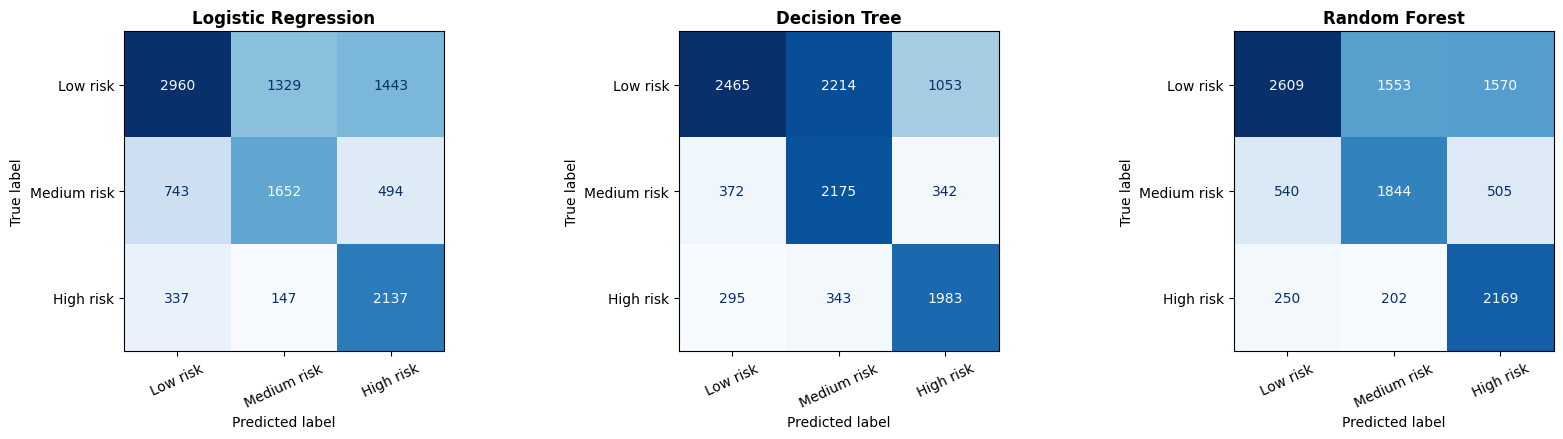

Classification report for the best model: Logistic Regression

              precision    recall  f1-score   support

    Low risk       0.73      0.52      0.61      5732
 Medium risk       0.53      0.57      0.55      2889
   High risk       0.52      0.82      0.64      2621

    accuracy                           0.60     11242
   macro avg       0.60      0.63      0.60     11242
weighted avg       0.63      0.60      0.60     11242



In [ ]:
fig, axes = plt.subplots(1, len(fitted_models), figsize=(17, 4.5))
if len(fitted_models) == 1:
    axes = [axes]

for ax, (model_name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=target_order)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_order)
    disp.plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(model_name, fontweight='bold')
    ax.tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.show()

print(f'Classification report for the best model: {best_model_name}\n')
print(classification_report(
    y_test,
    predictions[best_model_name],
    labels=target_order,
    zero_division=0
))


### 4.5 Interpret the Best Performing Model

The model interpretation is based on the best-performing model identified by **Macro F1-score**. This is important because the best model may not always be the most complex model, and it may change after feature engineering or missing-value threshold adjustment.

If Logistic Regression performs best, the interpretation focuses on its coefficients. Larger positive coefficients indicate variables associated with a higher likelihood of a specific risk class, while larger negative coefficients indicate variables associated with a lower likelihood of that class. If a tree-based model such as Decision Tree or Random Forest performs best, the interpretation uses feature importance to show which variables contributed most often to splitting the risk groups. These results should be interpreted as model-based associations, not causal effects.


Interpreting best model: Logistic Regression
Class interpreted: High risk

Top positive coefficients: variables associated with higher predicted probability


,Feature,Coefficient
215,Municipality of Residence ID_130180.0,1.410775
248,Municipality of Residence ID_130430.0,1.326270
57,Municipality ID_130180,1.319222
42,Municipality ID_130063,1.283386
62,Municipality ID_130230,1.198250
85,Municipality ID_130423,1.162933
246,Municipality of Residence ID_130423.0,1.096737
87,Municipality ID_130430,1.078276
189,Municipality of Residence ID_130002.0,1.077433
199,Municipality of Residence ID_130063.0,1.052399



Top negative coefficients: variables associated with lower predicted probability


,Feature,Coefficient
198,Municipality of Residence ID_130060.0,-2.455893
235,Municipality of Residence ID_130353.0,-2.089516
82,Municipality ID_130406,-2.021727
50,Municipality ID_130120,-1.976676
214,Municipality of Residence ID_130170.0,-1.894509
245,Municipality of Residence ID_130420.0,-1.851801
58,Municipality ID_130185,-1.729241
71,Municipality ID_130320,-1.537995
56,Municipality ID_130170,-1.420847
223,Municipality of Residence ID_130250.0,-1.285943


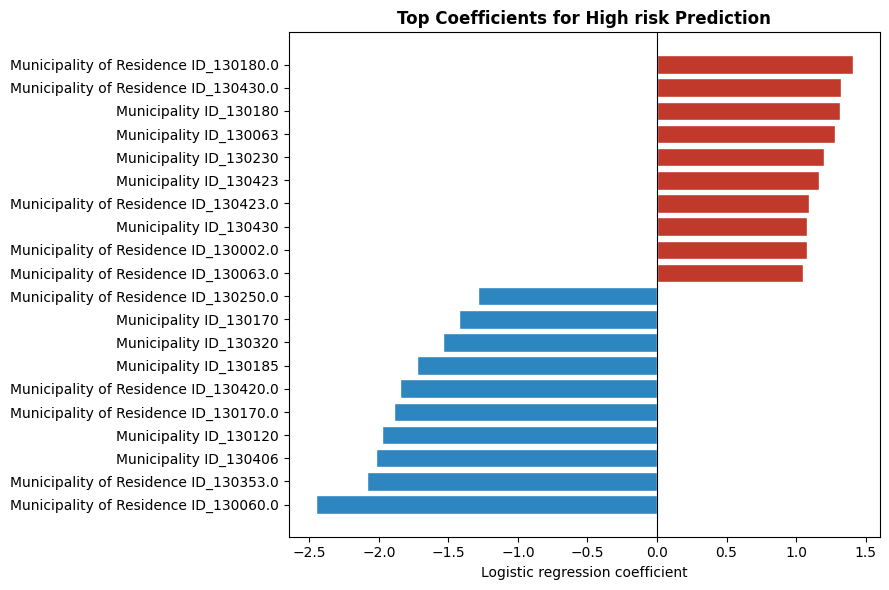

In [ ]:
best_pipeline = fitted_models[best_model_name]
best_estimator = best_pipeline.named_steps['model']
preprocessor = best_pipeline.named_steps['preprocess']

try:
    feature_names = preprocessor.get_feature_names_out()
except AttributeError:
    ohe = preprocessor.named_transformers_['categorical'].named_steps['onehot']
    encoded_categorical = ohe.get_feature_names_out(categorical_features)
    feature_names = np.r_[numeric_features, encoded_categorical]

feature_names = pd.Series(feature_names).str.replace('numeric__', '', regex=False).str.replace('categorical__', '', regex=False)
print(f'Interpreting best model: {best_model_name}')

if hasattr(best_estimator, 'coef_'):
    coef = best_estimator.coef_
    classes = list(best_estimator.classes_)

    # Show coefficients for the High risk class because it is the most important
    # class for public-health priority attention.
    if 'High risk' in classes:
        class_index = classes.index('High risk')
    else:
        class_index = int(np.argmax(np.mean(np.abs(coef), axis=1)))

    high_risk_coef = pd.DataFrame({
        'Feature': feature_names,
        'Coefficient': coef[class_index]
    })

    positive_coef = high_risk_coef.sort_values('Coefficient', ascending=False).head(10)
    negative_coef = high_risk_coef.sort_values('Coefficient', ascending=True).head(10)

    print(f'Class interpreted: {classes[class_index]}')
    print('\nTop positive coefficients: variables associated with higher predicted probability')
    display(positive_coef)
    print('\nTop negative coefficients: variables associated with lower predicted probability')
    display(negative_coef)

    plot_coef = pd.concat([
        positive_coef.assign(Direction='Positive'),
        negative_coef.assign(Direction='Negative')
    ]).sort_values('Coefficient')

    plt.figure(figsize=(9, 6))
    colors = ['#C0392B' if value > 0 else '#2E86C1' for value in plot_coef['Coefficient']]
    plt.barh(plot_coef['Feature'], plot_coef['Coefficient'], color=colors, edgecolor='white')
    plt.axvline(0, color='black', linewidth=0.8)
    plt.xlabel('Logistic regression coefficient')
    plt.title(f'Top Coefficients for {classes[class_index]} Prediction', fontweight='bold')
    plt.tight_layout()
    plt.show()

elif hasattr(best_estimator, 'feature_importances_'):
    importance_df = pd.DataFrame({
        'Feature': feature_names,
        'Importance': best_estimator.feature_importances_
    }).sort_values('Importance', ascending=False)

    top_importance = importance_df.head(15).copy()
    display(top_importance)

    plt.figure(figsize=(9, 5))
    plt.barh(
        top_importance['Feature'][::-1],
        top_importance['Importance'][::-1],
        color='steelblue',
        edgecolor='white'
    )
    plt.xlabel('Feature importance')
    plt.title(f'Top 15 Feature Importances for {best_model_name}', fontweight='bold')
    plt.tight_layout()
    plt.show()

else:
    print('The selected model does not provide direct coefficient or feature-importance values.')


### 4.6 Modeling Interpretation

The final model is selected mainly by **Macro F1-score**, because this metric gives equal importance to low-, medium- and high-risk classes. **High risk recall** is also reviewed because missing severe dengue cases would be more harmful from a public-health perspective.

The three-class output supports the Section 1 objective of high-risk population profiling: low-risk cases can be managed routinely, while medium- and high-risk cases can be treated as priority-attention groups for earlier monitoring and resource planning.

The model should be interpreted as a risk-profiling tool, not a standalone clinical diagnostic system. The results show model-based associations only, and very sparse or post-event variables are excluded to reduce noise and target leakage.


## Section 5:Evaluation


### 5.1 Evaluate Results
This section evaluates whether the modelling results meet the project's business and data mining objectives. The evaluation uses the held-out 20% test set created in Section 4, so the results reflect model performance on records not used during training.

The main evaluation focus is not only overall accuracy. For dengue risk profiling, High risk recall is especially important because a false negative means that a severe dengue patient may not be prioritised for early monitoring or intervention. Macro F1-score is also used as the main model-selection metric because it gives equal weight to Low, Medium and High risk groups.

Based on the current executed modelling results, Logistic Regression is the best-performing model by Macro F1-score. It achieves the strongest overall balance across the three risk classes and gives the highest recall for the High risk group. This is useful for public-health decision making because the model is also easier to explain than a black-box model.

In [ ]:
# Section 5.1 - Detailed model evaluation from Section 4 outputs
# This cell reuses results_df, predictions, fitted_models, y_test and target_order
# created during the modelling phase.

from sklearn.metrics import classification_report, confusion_matrix

if 'results_df' not in globals() or 'predictions' not in globals():
    raise RuntimeError('Please run Section 4 before running Section 5 evaluation cells.')

evaluation_summary = results_df.copy()
print('Overall model comparison on the held-out test set:')
display(evaluation_summary.style.format('{:.4f}'))

per_class_reports = {}
high_risk_records = []

for model_name, y_pred in predictions.items():
    report = classification_report(
        y_test,
        y_pred,
        labels=target_order,
        output_dict=True,
        zero_division=0
    )

    per_class_df = (
        pd.DataFrame(report)
        .T
        .loc[target_order, ['precision', 'recall', 'f1-score', 'support']]
        .round(4)
    )
    per_class_reports[model_name] = per_class_df

    cm = confusion_matrix(y_test, y_pred, labels=target_order)
    high_idx = target_order.index('High risk')
    high_support = cm[high_idx, :].sum()
    high_correct = cm[high_idx, high_idx]
    high_false_negative = high_support - high_correct
    high_false_positive = cm[:, high_idx].sum() - high_correct

    high_risk_records.append({
        'Model': model_name,
        'High Risk Precision': report['High risk']['precision'],
        'High Risk Recall': report['High risk']['recall'],
        'High Risk F1': report['High risk']['f1-score'],
        'High Risk Support': int(high_support),
        'High Risk False Negatives': int(high_false_negative),
        'High Risk FN Rate': high_false_negative / high_support if high_support else 0,
        'High Risk False Positives': int(high_false_positive)
    })

high_risk_evaluation = (
    pd.DataFrame(high_risk_records)
    .set_index('Model')
    .sort_values('High Risk Recall', ascending=False)
)

print('\nHigh-risk class evaluation:')
display(high_risk_evaluation.round(4))

print(f'\nPer-class report for selected best model: {best_model_name}')
display(per_class_reports[best_model_name])

Overall model comparison on the held-out test set:


,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
Model,,,,,,
Logistic Regression,0.6003,0.6345,0.5951,0.6345,0.5978,0.5988
Decision Tree,0.5891,0.6465,0.6112,0.6465,0.5960,0.5844
Random Forest,0.5890,0.6403,0.5970,0.6403,0.5906,0.5848



High-risk class evaluation:


,High Risk Precision,High Risk Recall,High Risk F1,High Risk Support,High Risk False Negatives,High Risk FN Rate,High Risk False Positives
Model,,,,,,,
Random Forest,0.5111,0.8275,0.6319,2621,452,0.1725,2075
Logistic Regression,0.5245,0.8153,0.6384,2621,484,0.1847,1937
Decision Tree,0.5870,0.7566,0.6611,2621,638,0.2434,1395



Per-class report for selected best model: Logistic Regression


,precision,recall,f1-score,support
Low risk,0.7327,0.5164,0.6058,5732.0
Medium risk,0.5281,0.5718,0.5491,2889.0
High risk,0.5245,0.8153,0.6384,2621.0


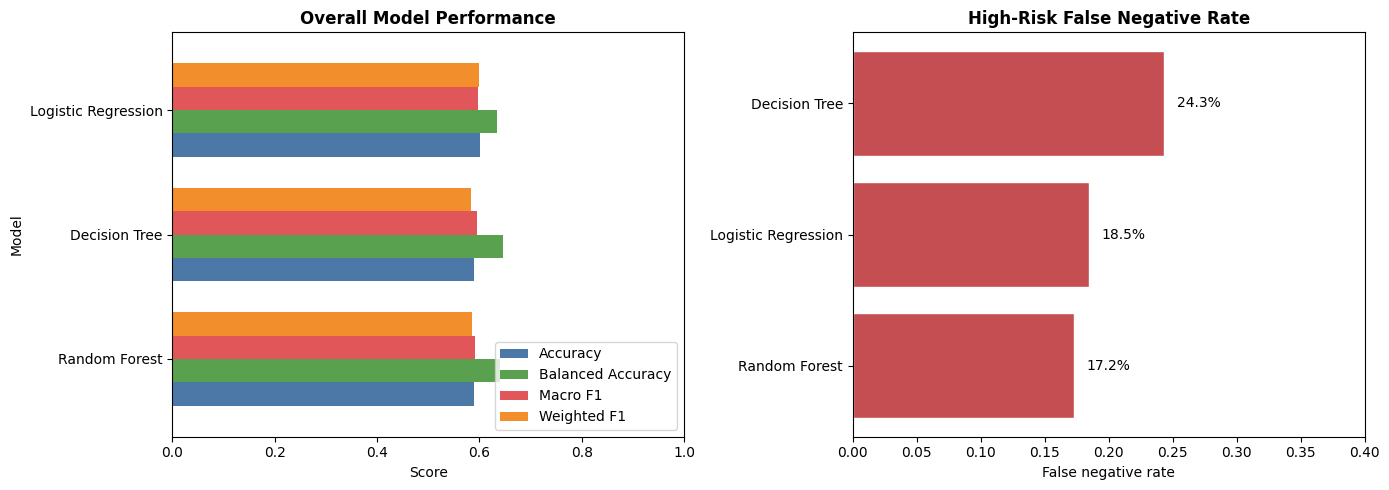

In [ ]:
# Visual comparison of model performance and high-risk false-negative rate

metric_columns = ['Accuracy', 'Balanced Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1', 'Weighted F1']
plot_df = evaluation_summary[metric_columns].sort_values('Macro F1', ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_df[['Accuracy', 'Balanced Accuracy', 'Macro F1', 'Weighted F1']].plot(
    kind='barh',
    ax=axes[0],
    width=0.75,
    color=['#4C78A8', '#59A14F', '#E15759', '#F28E2B']
)
axes[0].set_title('Overall Model Performance', fontweight='bold')
axes[0].set_xlabel('Score')
axes[0].set_xlim(0, 1)
axes[0].legend(loc='lower right')

fn_plot = high_risk_evaluation.sort_values('High Risk FN Rate', ascending=True)
axes[1].barh(fn_plot.index, fn_plot['High Risk FN Rate'], color='#C44E52', edgecolor='white')
axes[1].set_title('High-Risk False Negative Rate', fontweight='bold')
axes[1].set_xlabel('False negative rate')
axes[1].set_xlim(0, max(0.4, fn_plot['High Risk FN Rate'].max() + 0.05))

for i, value in enumerate(fn_plot['High Risk FN Rate']):
    axes[1].text(value + 0.01, i, f'{value:.1%}', va='center')

plt.tight_layout()
plt.show()

Evaluation interpretation

The model comparison shows that the expected advantage of Random Forest is not observed in this run. Logistic Regression performs best on Macro F1-score, which means it provides the most balanced performance across the Low, Medium and High risk classes. Its High risk recall is also strong, meaning most severe dengue cases in the test set are correctly flagged.

However, the model is not perfect. Some Low risk and Medium risk cases are still confused with higher-risk groups, and the overall accuracy is moderate. For a public-health prototype this trade-off is acceptable because over-prioritising some patients is less harmful than missing severe cases. For direct clinical use, the model would require stronger validation, external testing and clinical review.

Overall, the model meets the project objective as a risk-profiling and policy-support tool, but it should not be presented as a standalone diagnostic system.

In [ ]:
# Business-objective evaluation table

best_metrics = evaluation_summary.loc[best_model_name]
best_high_risk = high_risk_evaluation.loc[best_model_name]

business_evaluation = pd.DataFrame([
    {
        'Evaluation Area': 'Identify high-risk population groups',
        'Success Indicator': 'High risk recall >= 0.80',
        'Observed Result': f"{best_high_risk['High Risk Recall']:.4f}",
        'Status': 'Met' if best_high_risk['High Risk Recall'] >= 0.80 else 'Partially met',
        'Interpretation': 'The selected model captures most severe dengue cases for priority attention.'
    },
    {
        'Evaluation Area': 'Balanced classification across risk levels',
        'Success Indicator': 'Macro F1 >= 0.55',
        'Observed Result': f"{best_metrics['Macro F1']:.4f}",
        'Status': 'Met' if best_metrics['Macro F1'] >= 0.55 else 'Partially met',
        'Interpretation': 'The selected model performs reasonably across Low, Medium and High risk groups.'
    },
    {
        'Evaluation Area': 'Public-health interpretability',
        'Success Indicator': 'Best model can be explained to policy users',
        'Observed Result': best_model_name,
        'Status': 'Met' if best_model_name == 'Logistic Regression' else 'Partially met',
        'Interpretation': 'The selected model can be explained using coefficients and risk-associated features.'
    },
    {
        'Evaluation Area': 'Resource allocation support',
        'Success Indicator': 'Model separates priority-attention cases from routine cases',
        'Observed Result': f"Balanced accuracy = {best_metrics['Balanced Accuracy']:.4f}",
        'Status': 'Partially met' if best_metrics['Balanced Accuracy'] < 0.75 else 'Met',
        'Interpretation': 'The prototype can support prioritisation, but should be improved before operational deployment.'
    }
])

display(business_evaluation)

,Evaluation Area,Success Indicator,Observed Result,Status,Interpretation
0,Identify high-risk population groups,High risk recall >= 0.80,0.8153,Met,The selected model captures most severe dengue...
1,Balanced classification across risk levels,Macro F1 >= 0.55,0.5978,Met,The selected model performs reasonably across ...
2,Public-health interpretability,Best model can be explained to policy users,Logistic Regression,Met,The selected model can be explained using coef...
3,Resource allocation support,Model separates priority-attention cases from ...,Balanced accuracy = 0.6345,Partially met,"The prototype can support prioritisation, but ..."


### 5.2 Review Process
A review of the data mining process was conducted to identify strengths, limitations and improvements before deployment.

Business understanding: The project objective is consistent with the modelling output because the model classifies dengue cases into Low, Medium and High risk groups. This supports targeted monitoring, public awareness and resource planning. A clearer numeric success threshold should be defined at the start of future work.

Data understanding and preparation: The SINAN patient-level dataset provides useful demographic, symptom and clinical classification fields. The cleaning process removed highly incomplete fields and implausible age records. However, some potentially useful variables were lost because of missingness, and the dataset does not include environmental drivers such as rainfall, temperature, mosquito density or vaccination history.

Modeling: Three models were compared using the same train-test split and preprocessing pipeline. Class weights were used to reduce the impact of class imbalance. The best model was selected using Macro F1-score, which is more suitable than accuracy alone for imbalanced health data.

Evaluation: The evaluation considers both technical metrics and public-health consequences. High risk recall is treated as a priority because missed severe dengue cases are more harmful than false alarms. The model is therefore suitable as an early risk-screening prototype, but not as a final clinical diagnosis tool.



In [ ]:
# Process review checklist

process_review = pd.DataFrame([
    {
        'Phase': 'Business Understanding',
        'What Worked': 'Clear focus on risk profiling and targeted public-health intervention.',
        'Limitation': 'Success thresholds were not fully specified at the beginning.',
        'Improvement Action': 'Define minimum Macro F1, High risk recall and acceptable false-negative rate before modelling.'
    },
    {
        'Phase': 'Data Understanding',
        'What Worked': 'Key demographic, symptom and classification fields were explored.',
        'Limitation': 'Environmental and vaccination-related variables are not available in the current dataset.',
        'Improvement Action': 'Add rainfall, temperature, mosquito index, region-level population and vaccination coverage data.'
    },
    {
        'Phase': 'Data Preparation',
        'What Worked': 'Missing-value filtering, translation and age decoding made the data usable for modelling.',
        'Limitation': 'Dropping high-missingness columns may remove clinically meaningful signals.',
        'Improvement Action': 'Test alternative missing-value thresholds and missingness indicators in future experiments.'
    },
    {
        'Phase': 'Modeling',
        'What Worked': 'Pipelines ensured consistent imputation, encoding and model training.',
        'Limitation': 'Only a single hold-out split was used; hyperparameter tuning was limited.',
        'Improvement Action': 'Use stratified cross-validation and tune all model families consistently.'
    },
    {
        'Phase': 'Evaluation',
        'What Worked': 'Macro metrics and High risk recall were used instead of accuracy alone.',
        'Limitation': 'No external validation dataset was used.',
        'Improvement Action': 'Validate on a later year or a different region before deployment.'
    }
])

display(process_review)

,Phase,What Worked,Limitation,Improvement Action
0,Business Understanding,Clear focus on risk profiling and targeted pub...,Success thresholds were not fully specified at...,"Define minimum Macro F1, High risk recall and ..."
1,Data Understanding,"Key demographic, symptom and classification fi...",Environmental and vaccination-related variable...,"Add rainfall, temperature, mosquito index, reg..."
2,Data Preparation,"Missing-value filtering, translation and age d...",Dropping high-missingness columns may remove c...,Test alternative missing-value thresholds and ...
3,Modeling,"Pipelines ensured consistent imputation, encod...",Only a single hold-out split was used; hyperpa...,Use stratified cross-validation and tune all m...
4,Evaluation,Macro metrics and High risk recall were used i...,No external validation dataset was used.,Validate on a later year or a different region...


###5.3 Determine Next Steps
Based on the evaluation, the project should move forward as a prototype dengue risk-profiling system rather than a final deployment-ready clinical tool.

The most important next step is to improve reliability through validation and richer data. The current model already supports the business goal of identifying priority-attention dengue cases, but operational use would require external validation, regular monitoring and integration with public-health workflows.

Following model evaluation, follow-up improvements are sorted by priority. Three high-priority tasks include stratified cross-validation to verify model stability across data splits, time-series holdout validation to test generalization on future dengue outbreaks, and threshold/cost-sensitive optimisation to cut high-risk false negatives for better public health protection. Medium-priority plans cover incorporating meteorological and geographic features to capture epidemic drivers, developing an interpretable dashboard to support health authority decision-making, and establishing periodic monitoring and retraining rules to cope with shifting dengue epidemic trends. Overall, the model is suggested to proceed toward monitored prototype deployment, while extra external validation is mandatory prior to formal clinical implementation.

In [ ]:
# Recommended next steps after evaluation

next_steps = pd.DataFrame([
    {
        'Priority': 'High',
        'Next Step': 'Run stratified cross-validation',
        'Purpose': 'Check whether model performance is stable across different train-test splits.',
        'Expected Output': 'Mean and standard deviation of Macro F1 and High risk recall.'
    },
    {
        'Priority': 'High',
        'Next Step': 'Validate on a time-based holdout set',
        'Purpose': 'Test whether the model generalises to future dengue seasons.',
        'Expected Output': 'Performance comparison on later-year records.'
    },
    {
        'Priority': 'High',
        'Next Step': 'Reduce high-risk false negatives',
        'Purpose': 'Improve public-health safety by identifying more severe cases.',
        'Expected Output': 'Threshold tuning or cost-sensitive model with lower High risk FN rate.'
    },
    {
        'Priority': 'Medium',
        'Next Step': 'Add environmental and regional variables',
        'Purpose': 'Capture outbreak drivers not present in patient-only data.',
        'Expected Output': 'Expanded model with rainfall, temperature, location and population context.'
    },
    {
        'Priority': 'Medium',
        'Next Step': 'Build an explainable dashboard prototype',
        'Purpose': 'Translate model output into actionable public-health decisions.',
        'Expected Output': 'Dashboard showing risk distribution, high-risk profiles and model confidence.'
    },
    {
        'Priority': 'Medium',
        'Next Step': 'Create monitoring and retraining plan',
        'Purpose': 'Keep model performance reliable as dengue patterns change.',
        'Expected Output': 'Monthly performance checks, quarterly drift checks and retraining trigger rules.'
        }
])

display(next_steps)

print('Recommended decision: continue to deployment planning as a monitored prototype, with external validation required before real-world clinical use.')

,Priority,Next Step,Purpose,Expected Output
0,High,Run stratified cross-validation,Check whether model performance is stable acro...,Mean and standard deviation of Macro F1 and Hi...
1,High,Validate on a time-based holdout set,Test whether the model generalises to future d...,Performance comparison on later-year records.
2,High,Reduce high-risk false negatives,Improve public-health safety by identifying mo...,Threshold tuning or cost-sensitive model with ...
3,Medium,Add environmental and regional variables,Capture outbreak drivers not present in patien...,"Expanded model with rainfall, temperature, loc..."
4,Medium,Build an explainable dashboard prototype,Translate model output into actionable public-...,"Dashboard showing risk distribution, high-risk..."
5,Medium,Create monitoring and retraining plan,Keep model performance reliable as dengue patt...,"Monthly performance checks, quarterly drift ch..."


Recommended decision: continue to deployment planning as a monitored prototype, with external validation required before real-world clinical use.


# Section 6: Deployment
## 6.1 Plan Deployment
### Deployment Plan

The deployment phase translates the trained risk-profiling model into functional, proactive tools that support public health policy, resource allocation, and targeted interventions.

To directly address the project's business objectives, we propose a Dual-Impact Public Health Architecture serving both government decision-makers and the general public:

- **Tier 1: MOH Policy & Intervention Dashboard:** An aggregated, predictive view for Ministry of Health (MOH) officials and epidemiologists to identify impending high-risk zones, allocate early vector control resources, and plan targeted dengue vaccination rollouts.
  
- **Tier 2: Targeted Public Awareness System:** An automated risk-alert engine designed to be integrated with local health applications (e.g., MySejahtera) to send early-warning notifications and preventive guidelines to demographic groups identified as highly susceptible.



### Target User Groups

**1. MOH Policymakers and Epidemiologists** These users will leverage the Tier 1 dashboard to support macro-level decision-making. By analyzing model predictions, they can justify and design targeted vaccination strategies, assessing which demographic segments or regions will yield the highest health benefits (ROI) compared to broad mass-vaccination programs.

**2. Local Health Offices & Vector Control Teams** Instead of relying on reactive fogging after an outbreak occurs, local teams can use the model's short-term regional predictions to conduct early, preventative vector control and community clean-up operations in identified high-risk zones.

**3. The General Public (High-Risk Segments)** Through the Tier 2 system, individuals belonging to high-risk profiles will receive targeted health advisories prior to peak dengue seasons. This fulfills the business objective of improving public compliance with prevention measures outside of active outbreak periods.



### Susceptible Population Profiles

One of the analytical goals of this project is to characterise which population segments appear more frequently among dengue-positive cases. Based on the features available in the dataset, several dimensions are worth examining:

| Dimension | Features Used | Hypothesis |
|-----------|--------------|------------|
| **Age group** | `NU_IDADE_N` | Elderly and young children may present with more severe symptom profiles |
| **Residence zone** | `CS_ZONA` | Urban and peri-urban populations may have higher exposure due to density |
| **Gender** | `CS_SEXO` | To be assessed; no strong prior assumption |
| **Pregnancy** | `CS_GESTANT` | Pregnant individuals are a clinically distinct group worth flagging separately |
| **Medical conditions** | `DIABETES`, `HIPERTENSA`, `RENAL`, `HEPATOPAT`, `AUTO_IMUNE`, etc. | Comorbidities *may* correlate with case severity or classification; this will be examined during EDA but is not assumed |

> **Note on comorbidities:** Whether medical history meaningfully predicts dengue susceptibility, as opposed to influencing case severity, is an open question that will be investigated during the modelling phase. The deployment will reflect whatever the data supports, rather than assuming a relationship in advance.

These profiles would be surfaced in the population dashboard as summary statistics, allowing officials to see, for example, whether patients with hypertension or diabetes are disproportionately represented among confirmed dengue cases in a given period.



### Deployment Platform

| Option | Suitability | Decision |
|--------|-------------|-----------|
| Streamlit | Low overhead, suitable for prototyping and academic demonstration | Adopted |
| FastAPI | Better for production integration with hospital or government systems | Future scope |

## 6.2 Plan Monitoring and Maintenance
### *Monitoring and Maintenance Plan*

Dengue incidence is seasonal and geographically uneven. The demographic and symptomatic profile of patients presenting at clinics shifts across outbreak cycles, meaning a model trained on historical data may gradually lose relevance if left unmonitored. Active maintenance is therefore not optional, it is a structural part of the deployment.

### Monitoring Strategy

| Metric | Method | Frequency |
|--------|--------|-----------|
| Predictive performance | Evaluate F1-score and AUC-ROC against newly confirmed cases | Monthly |
| Data drift | Monitor statistical distribution of input features for significant shifts | Quarterly |
| Confidence distribution | Track average prediction confidence; sustained drops signal distributional mismatch | Ongoing |
| Population profile shifts | Monitor whether the demographic composition of incoming cases changes materially | Quarterly |
| User-flagged discrepancies | Allow clinical staff to mark predictions that did not align with eventual diagnosis | Ongoing |

### Retraining Criteria

Retraining will be triggered when the F1-score on recent cases falls below **0.80**, or when a statistically significant shift in the input feature distribution is detected. The retrained model will be validated against a held-out set before replacing the current version.

Model and dataset versions will be tracked using **MLflow** or **DVC**, ensuring reproducibility and the ability to roll back if a new version underperforms.

### Prediction Logging

All predictions will be logged with timestamps and anonymised input features. Beyond serving as an audit trail, this log is the primary source of data for future retraining cycles and for longitudinal analysis of how susceptible population profiles evolve over time.

## 6.3 Produce Final Report
### *Final Report*

The final report will consolidate findings across all project phases, covering the model's predictive performance, the population profiles identified, and the rationale behind key design decisions. It will also address known limitations and outline what additional steps would be needed to move the prototype toward responsible real-world deployment.

## 6.4 Review Project
### *Experience Documentation*

This section will be completed upon project conclusion. It will document what worked well, what did not, and what the team would approach differently, covering both technical decisions and the broader challenge of designing a tool that is useful across such different user groups.